In [84]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Load the dataset
# Replace 'path_to_your_dataset.csv' with the actual file path where you saved the dataset
df = pd.read_csv(r'C:\Users\M\Desktop\ironhacker\amazon\archive (6)\amz_uk_price_prediction_dataset.csv')

# Preview the first few rows
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [85]:
df = df[df.columns[df.isnull().mean() < 0.8]]

In [86]:
df.drop("uid", inplace=True, axis=1)

In [87]:
# Crosstab between category and isBestSeller status
crosstab = pd.crosstab(df['category'], df['isBestSeller'])
crosstab

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [88]:
# Adding a new column for the proportion of best-sellers in each category
crosstab['best_seller_proportion'] = crosstab[True] / (crosstab[True] + crosstab[False])

# Sorting by the proportion of best-sellers in descending order
crosstab_sorted = crosstab.sort_values(by='best_seller_proportion', ascending=False)

# Display the top categories with the highest proportion of best-sellers
crosstab_sorted.head()

isBestSeller,False,True,best_seller_proportion
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339


--- In grocery the proportion of best-sellers is higher based on the sorted crosstab.

In [90]:
# Chi-square test to check if isBestSeller is independent of product category
from scipy.stats import chi2_contingency

# Conduct Chi-square test
chi2, p, dof, expected = chi2_contingency(pd.crosstab(df['category'], df['isBestSeller']))

print(f"Chi-square Statistic: {chi2}")
print(f"P-value: {p}")



Chi-square Statistic: 36540.20270061387
P-value: 0.0


In [91]:
# Chi-square test for 'MSZoning' and 'SaleCondition'
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab)

chi2_statistic, chi2_p_value

(36684.23786636857, 0.0)

In [92]:
# Calculate Cramér's V to measure the strength of association
n = df.shape[0]
cramers_v = np.sqrt(chi2 / (n * (min(crosstab.shape) - 1)))

print(f"Cramér's V: {cramers_v}")

Cramér's V: 0.08646709890892415


Chi-square result: If the p-value is small (less than 0.05), the best-seller distribution is not independent of the category.

Cramér's V: The Cramér's V value of 0.086 suggests a weak association between the two variables. Though statistically significant, the strength of this relationship is not very strong in practical terms.

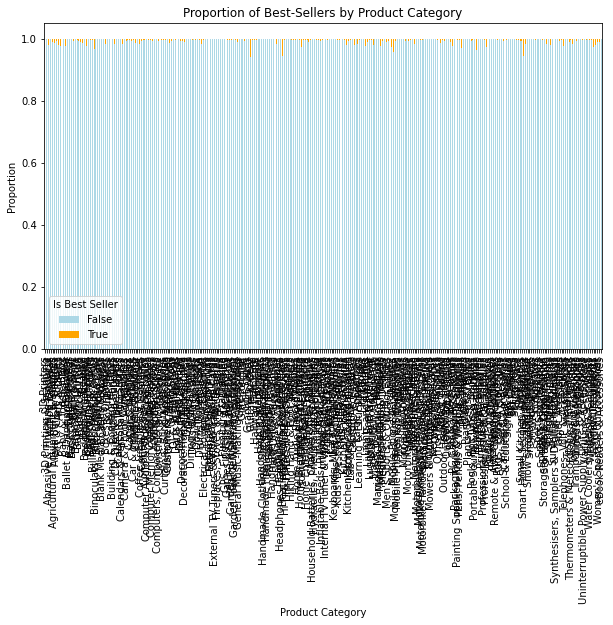

In [94]:
# Plotting a stacked bar chart for the relationship between category and isBestSeller
best_seller_counts = pd.crosstab(df['category'], df['isBestSeller'], normalize='index')

best_seller_counts.plot(kind='bar', stacked=True, figsize=(10, 6), color=['lightblue', 'orange'])
plt.title('Proportion of Best-Sellers by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Proportion')
plt.legend(title='Is Best Seller')
plt.show()


<Axes: xlabel='category'>

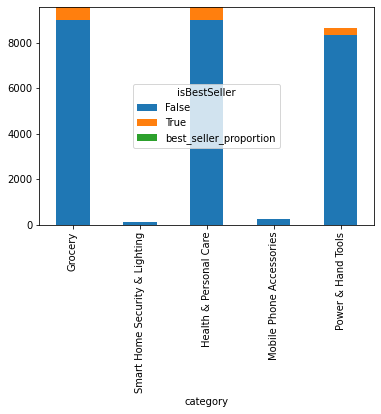

In [95]:
# Plotting a grouped bar chart
top_5=crosstab_sorted.head()
# Plotting a stacked bar chart for the 'crosstab_result' data
top_5.plot(kind="bar", stacked=True)

In [96]:
#part2: 
# Removing outliers using the IQR method
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Define outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter out the outliers
df_cleaned = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]


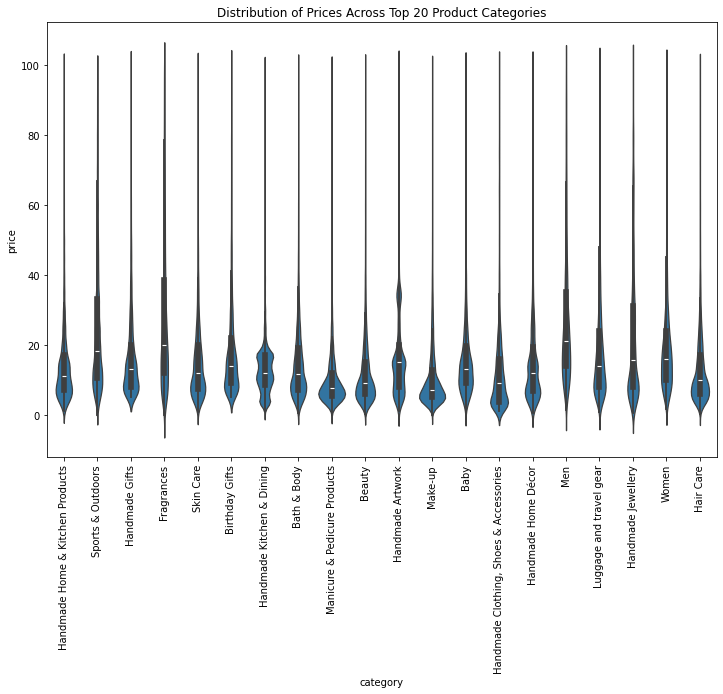

In [97]:
# Filtering the top 20 categories by count
top_20_categories = df_cleaned['category'].value_counts().nlargest(20).index

# Plotting the violin plot
plt.figure(figsize=(12, 8))
sns.violinplot(x='category', y='price', data=df_cleaned[df_cleaned['category'].isin(top_20_categories)])
plt.title('Distribution of Prices Across Top 20 Product Categories')
plt.xticks(rotation=90)
plt.show()


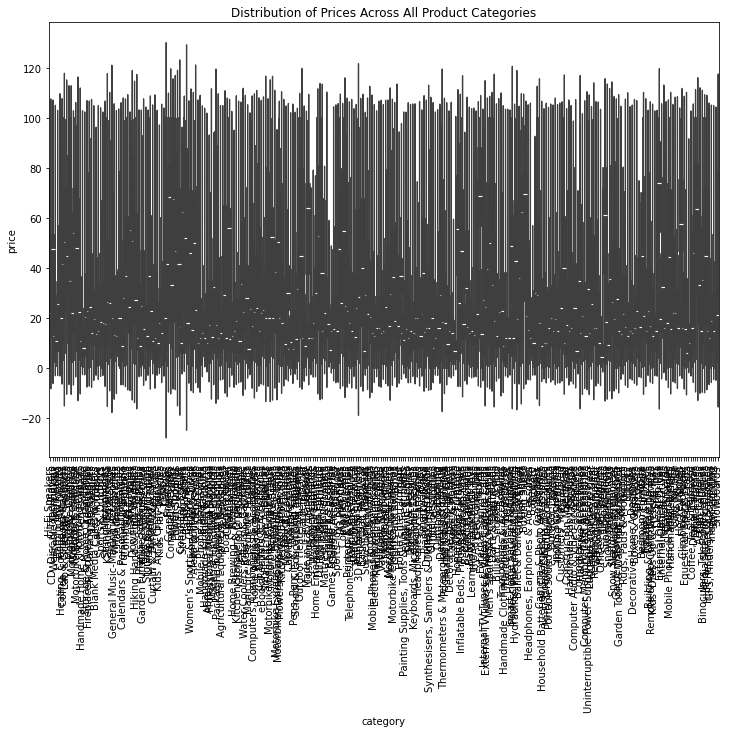

In [98]:
# Plotting a violin plot for price distribution across all product categories
plt.figure(figsize=(12, 8))
sns.violinplot(x='category', y='price', data=df_cleaned)  # No filter on categories
plt.title('Distribution of Prices Across All Product Categories')
plt.xticks(rotation=90)
plt.show()


----When there are too many categories, it becomes difficult to visually identify the category with the highest median price in the violin plot. A more efficient way to handle this is to directly calculate the median price for each category and then find the category with the highest median programmatically

In [100]:
# Calculate the median price for each category
median_prices = df_cleaned.groupby('category')['price'].median()

#Find the category with the highest median price
highest_median_category = median_prices.idxmax()  # Category with the highest median price
highest_median_price = median_prices.max()  # The highest median price value

print(f"The category with the highest median price is: {highest_median_category}")
print(f"The highest median price is: £{highest_median_price}")


The category with the highest median price is: Desktop PCs
The highest median price is: £74.0


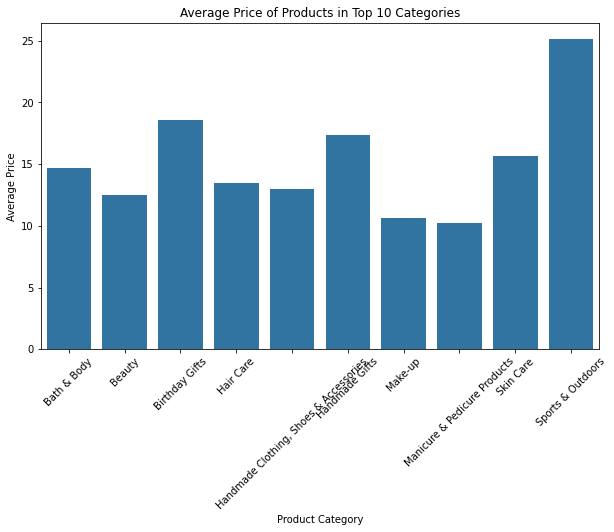

In [101]:
# Calculate the average price for the top 10 categories
top_10_categories = df_cleaned['category'].value_counts().nlargest(10).index
avg_price_per_category = df_cleaned[df_cleaned['category'].isin(top_10_categories)].groupby('category')['price'].mean()

# Plotting the bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x=avg_price_per_category.index, y=avg_price_per_category.values)
plt.title('Average Price of Products in Top 10 Categories')
plt.xlabel('Product Category')
plt.ylabel('Average Price')
plt.xticks(rotation=45)
plt.show()


----Which product category commands the highest average price? Don't filter here by top categories:                                                         I follow a similar approach to the median calculation from the previous step, but this time we'll focus on the average price for each category.

In [103]:
# Calculate the average price for each category
avg_prices = df_cleaned.groupby('category')['price'].mean()

# Find the category with the highest average price
highest_avg_category = avg_prices.idxmax()  # Category with the highest average price
highest_avg_price = avg_prices.max()  # The highest average price value

print(f"The category with the highest average price is: {highest_avg_category}")
print(f"The highest average price is: £{highest_avg_price:.2f}")


The category with the highest average price is: Motherboards
The highest average price is: £68.77


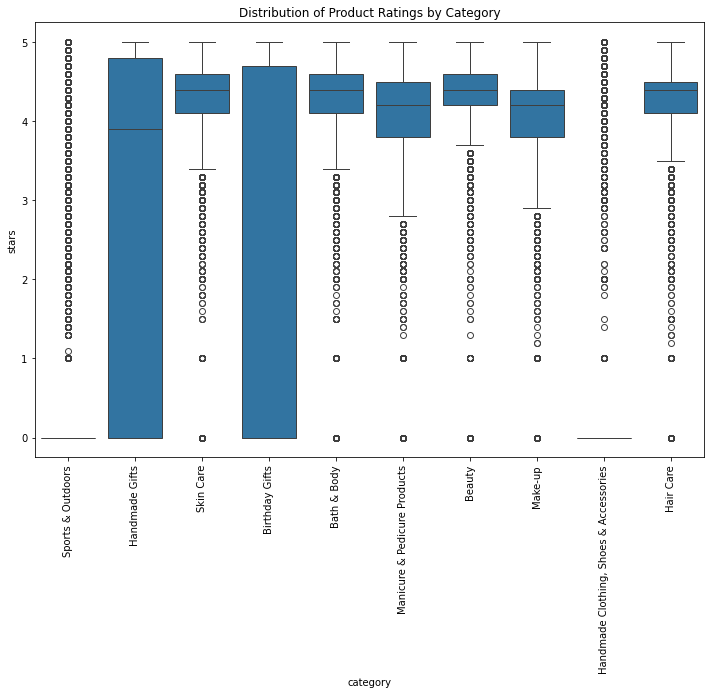

In [104]:
# Plotting box plots for the top 10 categories by rating distribution
plt.figure(figsize=(12, 8))
sns.boxplot(x='category', y='stars', data=df_cleaned[df_cleaned['category'].isin(top_10_categories)])
plt.title('Distribution of Product Ratings by Category')
plt.xticks(rotation=90)
plt.show()


In [105]:
# Calculate the median rating for each category
median_ratings = df_cleaned.groupby('category')['stars'].median()

# Find the category with the highest median rating
highest_median_rating_category = median_ratings.idxmax()  # Category with the highest median rating
highest_median_rating = median_ratings.max()  # The highest median rating value

print(f"The category with the highest median rating is: {highest_median_rating_category}")
print(f"The highest median rating is: {highest_median_rating}")


The category with the highest median rating is: Computer Memory
The highest median rating is: 4.7


In [106]:
df_rating_cleaned = df_cleaned[df_cleaned['stars'] > 0]

In [107]:
#part3:
# Calculate correlation coefficient between price and ratings
correlation = df_cleaned['price'].corr(df_cleaned['stars'])
print(f"Correlation between Price and Rating: {correlation}")


Correlation between Price and Rating: -0.07767299878181444


-- Suggesting a very weak relationship with ratings.

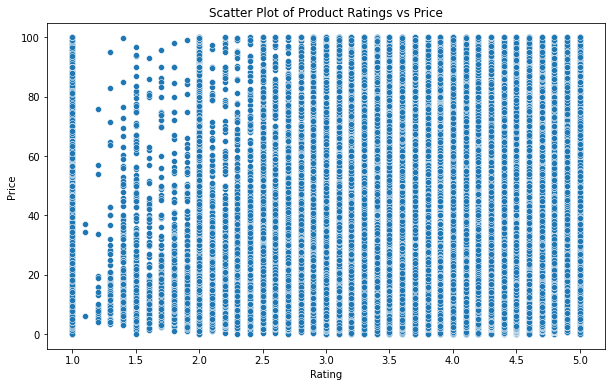

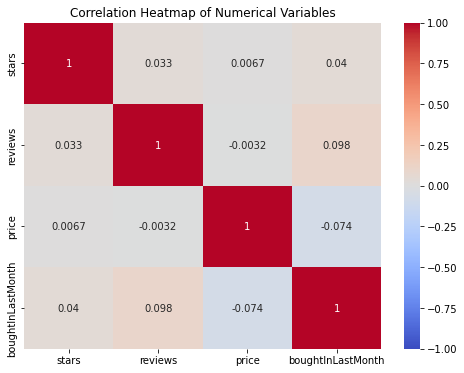

In [109]:
# Scatter plot to visualize price vs rating 
plt.figure(figsize=(10, 6))
sns.scatterplot(x='stars', y='price', data=df_rating_cleaned)
plt.title('Scatter Plot of Product Ratings vs Price')
plt.xlabel('Rating')
plt.ylabel('Price')
plt.show()

# Correlation heatmap for all numerical variables
# Filter out non-numeric columns
numeric_cols = df_rating_cleaned.select_dtypes(include=[np.number])  # Only numerical columns

# Generate the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Numerical Variables')
plt.show()




--- As previously mentioned, there is no significant pattern between price and ratings. Prices vary widely across different rating levels. However, from the scatter plot, we can observe a lower density of data points for ratings between 1(greater than 1) and 2.5.

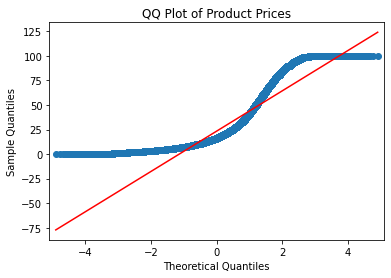

In [21]:
import statsmodels.api as sm

# QQ plot to check if product prices follow a normal distribution
sm.qqplot(df_cleaned['price'], line='s')
plt.title('QQ Plot of Product Prices')
plt.show()


---The product prices data is not normally distributed. Deviations of the data points from the red line, indicate deviations from normality.